# Regression NVDA DATA -DL TRAINING

In [11]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:
df = pd.read_csv(r"C:\Users\Dell\DL- NVDA-Regreesion  method\NVDA_stock.dataset.csv")
print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())
print("columns in the dataset:")
print(df.columns)


         Date   Open   High    Low  Close     Volume
0  2022-12-06  15.30  15.47  15.05  15.18  218015914
1  2022-12-07  15.23  15.27  14.92  15.14  185318803
2  2022-12-08  15.38  15.52  15.06  15.37  335932033
3  2022-12-09  15.85  15.97  15.78  15.91   89374000
4  2022-12-12  15.91  16.23  15.60  15.84  233076547
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1000 non-null   str    
 1   Open    1000 non-null   float64
 2   High    1000 non-null   float64
 3   Low     1000 non-null   float64
 4   Close   1000 non-null   float64
 5   Volume  1000 non-null   int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 56.8 KB
None
              Open         High          Low       Close        Volume
count  1000.000000  1000.000000  1000.000000  1000.00000  1.000000e+03
mean     24.001830    24.366460    23.638350    23.99159  1.558666e+08
std      10.554

In [13]:
# separate the features and target variable
X = df[["Open", "High", "Low", "Volume"]]
y = df["Close"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 4)
y shape: (1000,)


In [14]:
# train-test split
import sklearn.model_selection as train_test_split
X_train, X_test, y_train, y_test = train_test_split.train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (800, 4)
X_test shape: (200, 4)
y_train shape: (800,)
y_test shape: (200,)


In [15]:
# scaling the features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("first training rows:")
print(X_train[0])


first training rows:
[-0.99330733 -0.98449596 -0.99048649  0.91747604]


In [3]:
# creating ANN model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(16, activation="relu", input_shape=(4,)),
    Dense(8, activation="relu"),
    Dense(1, activation="linear")
])

model.summary()
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)
print("model compiled successfully:")

c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

model compiled successfully:


In [16]:
# train the ANN model
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 680.5549 - mean_absolute_error: 23.9076 - val_loss: 548.8558 - val_mean_absolute_error: 21.9859
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 660.6341 - mean_absolute_error: 23.5986 - val_loss: 532.9449 - val_mean_absolute_error: 21.6890
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 635.7980 - mean_absolute_error: 23.1975 - val_loss: 513.6805 - val_mean_absolute_error: 21.3174
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 606.5433 - mean_absolute_error: 22.7077 - val_loss: 490.4695 - val_mean_absolute_error: 20.8565
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 572.2111 - mean_absolute_error: 22.1014 - val_loss: 461.4733 - val_mean_absolute_error: 20.2639
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 529.4417 - mean_absolute_error: 21.3210 - val_loss: 427.0008 - val_mean_absolute_error: 19.5215
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 476.1820 - 

In [17]:
# PREDICTING THE TEST DATA
y_pred = model.predict(X_test)
print("first 5 predicted values:")
print(y_pred[:5])

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
first 5 predicted values:
[[23.133133]
 [19.382244]
 [20.631435]
 [22.460848]
 [23.441414]]


In [18]:
import pandas as pd

results = pd.DataFrame({
    "Actual_Close": y_test.values,
    "Predicted_Close": y_pred.flatten()
})

print(results.head(10))

   Actual_Close  Predicted_Close
0         23.05        23.133133
1         21.93        19.382244
2         22.39        20.631435
3         23.93        22.460848
4         23.83        23.441414
5         22.14        22.586430
6         25.21        26.582865
7         23.19        20.966599
8         29.65        30.513290
9         13.13        12.520885


In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("MSE:", mse)
print("MAE:", mae)

MSE: 2.046646834335438
MAE: 1.1283027070999148


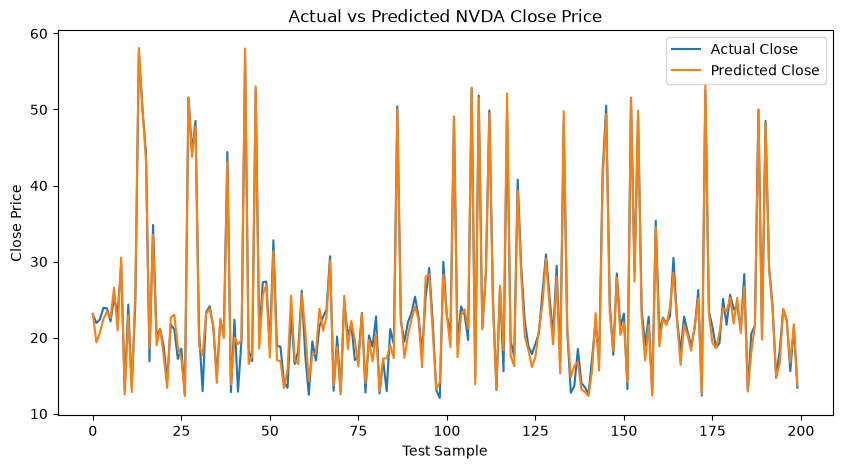

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    y_test.values,
    label="Actual Close"
)

plt.plot(
    y_pred.flatten(),
    label="Predicted Close"
)

plt.xlabel("Test Sample")
plt.ylabel("Close Price")
plt.title("Actual vs Predicted NVDA Close Price")
plt.legend()
plt.show()

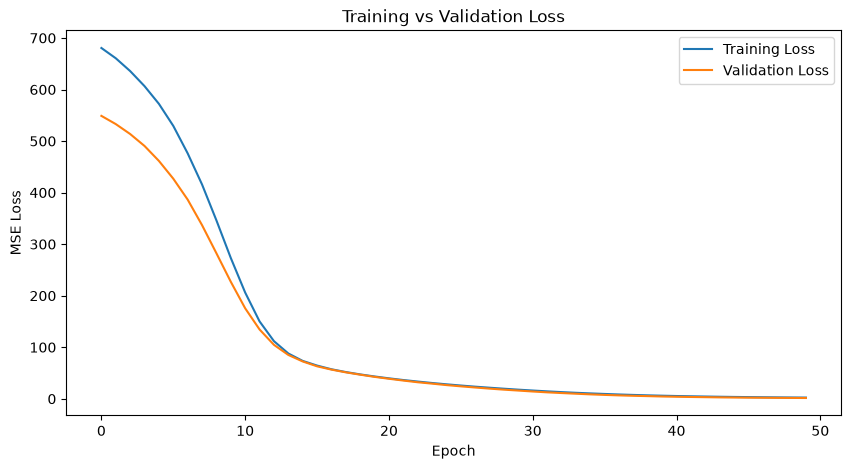

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [23]:
print(history.history.keys())

dict_keys(['loss', 'mean_absolute_error', 'val_loss', 'val_mean_absolute_error'])


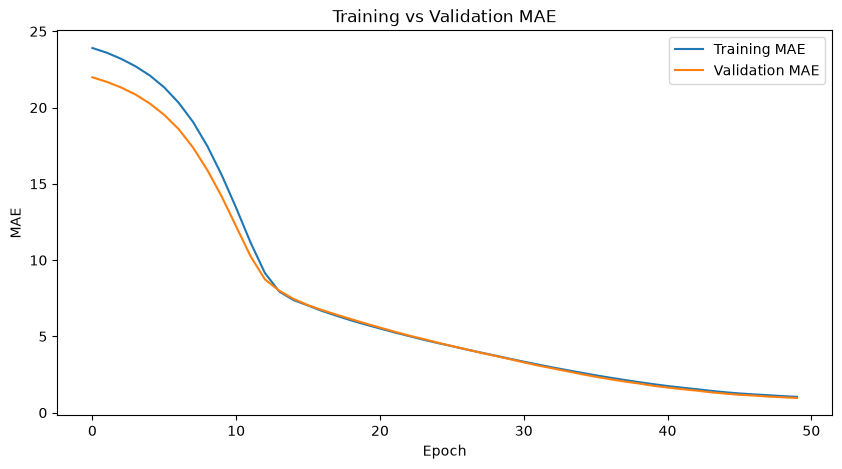

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["mean_absolute_error"],
    label="Training MAE"
)

plt.plot(
    history.history["val_mean_absolute_error"],
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training vs Validation MAE")
plt.legend()
plt.show()

In [25]:
model.save("nvda_ann_model.keras")

print("Model saved successfully!")

Model saved successfully!
